# Procesos de Gestión Humana - Deserción Laboral




---


## 1. Cargar Librerias



In [2]:
library(dplyr)
library(ggplot2)
library(readr)



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union






---


## 2. Cargar Información

In [3]:
df <- read.csv("/content/attrition_data.csv",sep=",")
df$STATUS <- as.factor(df$STATUS)
names(df)

[1] "EMP_ID"                 "ANNUAL_RATE"            "HRLY_RATE"             
 [4] "JOBCODE"                "ETHNICITY"              "SEX"                   
 [7] "MARITAL_STATUS"         "JOB_SATISFACTION"       "AGE"                   
[10] "NUMBER_OF_TEAM_CHANGED" "REFERRAL_SOURCE"        "HIRE_MONTH"            
[13] "REHIRE"                 "TERMINATION_YEAR"       "IS_FIRST_JOB"          
[16] "TRAVELLED_REQUIRED"     "PERFORMANCE_RATING"     "DISABLED_EMP"          
[19] "DISABLED_VET"           "EDUCATION_LEVEL"        "STATUS"                
[22] "JOB_GROUP"              "PREVYR_1"               "PREVYR_2"              
[25] "PREVYR_3"               "PREVYR_4"               "PREVYR_5"

|    | Variable               |   Tipo          | Descripción                                             |
|----|------------------------|-----------------|---------------------------------------------------------|
| 1  | EMP_ID                 | NUMERIC         | Identificador unico del empleado                        |     
| 2  | ANNUAL_RATE            | INTEGER         | Salario anual del empleado en dolares                   |
| 3  | HRLY_RATE              | INTEGER         | Salario por hora del empleado en dolares                |
| 4  | JOBCODE                | INTEGER         | Codigo numerico que identifica el tipo de trabajo       |
| 5  | ETHNICITY              | CHARACTER       | Grupo etnico del empleado                               |
| 6  | SEX                    | CHARACTER       | Sexo del empleado                                       |
| 7  | MARITAL_STATUS         | CHARACTER       | Estado civil del empleado                               |
| 8  | JOB_SATISFACTION       | INTEGER         | Nivel de satisfaccion laboral (escala numerica)         |
| 9  | AGE                    | INTEGER         | Edad del empleado en años                               |
| 10 | NUMBER_OF_TEAM_CHANGED | CHARACTER       | Numero de cambios de equipo realizados                  |
| 11 | REFERRAL_SOURCE        | CHARACTER       | Fuente mediante la cual el empleado fue referido        |
| 12 | HIRE_MONTH             | CHARACTER       | Mes en que fue contratado el empleado                   |
| 13 | REHIRE                 | CHARACTER       | Indica si el empleado fue recontratado                  |
| 14 | TERMINATION_YEAR       | INTEGER         | Año en que se termino la relacion laboral               |
| 15 | IS_FIRST_JOB           | CHARACTER       | Indica si este fue el primer empleo del trabajador      |
| 16 | TRAVELLED_REQUIRED     | CHARACTER       | Indica si se requieren viajes para el puesto            |
| 17 | PERFORMANCE_RATING     | INTEGER         | Calificacion del desempeno del empleado                 |
| 18 | DISABLED_EMP           | CHARACTER       | Calificacion del desempeno del empleado                 |
| 19 | DISABLED_VET           | CHARACTER       | Indica si el empleado es un veterano con discapacidad   |
| 20 | EDUCATION_LEVEL        | CHARACTER       | Nivel educativo del empleado                            |
| 21 | STATUS                 | CHARACTER       | Estado actual del empleado (activo o terminado)         |  
| 22 | JOB_GROUP              | CHARACTER       | Grupo o departamento de trabajo al que pertenece        |
| 23 | PREVYR_1               | INTEGER         | Desempeño del empleado en el año 1                      |
| 24 | PREVYR_2               | INTEGER         | Desempeño del empleado en el año 2                      |
| 25 | PREVYR_3               | INTEGER         | Desempeño del empleado en el año 3                      |
| 26 | PREVYR_4               | INTEGER         | Desempeño del empleado en el año 4                      |
| 27 | PREVYR_5               | INTEGER         | Desempeño del empleado en el año 5                      |



---


## 3. Análisis Univariado (Status)

### 3.1 Estatus

In [4]:
table(df$STATUS) #Conteo
prop.table(table(df$STATUS)) #Porcentajes


   A    T 
5394 4218 


        A         T 
0.5611735 0.4388265 

### 3.2 Edad

In [ ]:
df %>% group_by(STATUS) %>%
  summarise(
    media_edad = mean(AGE, na.rm = TRUE),
    mediana_edad = median(AGE, na.rm = TRUE),
    sd_edad = sd(AGE, na.rm = TRUE)
  )

STATUS,media_edad,mediana_edad,sd_edad
<fct>,<dbl>,<dbl>,<dbl>
A,39.84798,39,13.61062
T,40.53983,40,13.72465


### 3.3 Salario Anual

In [ ]:
df %>% group_by(STATUS) %>%
  summarise(
    media_salario = mean(ANNUAL_RATE, na.rm = TRUE),
    mediana_salario = median(ANNUAL_RATE, na.rm = TRUE)
  )

STATUS,media_salario,mediana_salario
<fct>,<dbl>,<dbl>
A,98604.85,80884.5
T,77596.03,68007.0


### 3.4 Salario por Hora

In [ ]:
df %>% group_by(STATUS) %>%
  summarise(
    media_hrly = mean(HRLY_RATE, na.rm = TRUE),
    mediana_hrly = median(HRLY_RATE, na.rm = TRUE)
  )

STATUS,media_hrly,mediana_hrly
<fct>,<dbl>,<dbl>
A,54.38283,46
T,44.28995,40


### 3.5 Satisfacción Laboral

In [ ]:
df %>% group_by(STATUS, JOB_SATISFACTION) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and JOB_SATISFACTION.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, JOB_SATISFACTION))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


STATUS,JOB_SATISFACTION,n,prop
<fct>,<int>,<int>,<dbl>
A,1,1294,0.2398962
A,2,1337,0.2478680
A,3,914,0.1694475
A,4,976,0.1809418
A,5,873,0.1618465
T,1,1054,0.2498815
T,2,1076,0.2550972
T,3,721,0.1709341
T,4,678,0.1607397


### 3.6 Estado Civil

In [ ]:
df %>% group_by(STATUS, MARITAL_STATUS) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and MARITAL_STATUS.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, MARITAL_STATUS))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


STATUS,MARITAL_STATUS,n,prop
<fct>,<chr>,<int>,<dbl>
A,Divorced,897,0.1662959
A,Married,2306,0.4275121
A,Single,2191,0.4061921
T,Divorced,708,0.1678521
T,Married,1721,0.4080133
T,Single,1789,0.4241347


### 3.7 Código de trabajo / rol

In [ ]:
df %>% group_by(STATUS, JOBCODE) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and JOBCODE.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, JOBCODE))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


STATUS,JOBCODE,n,prop
<fct>,<int>,<int>,<dbl>
A,10006,3,0.0005561735
A,10029,4,0.0007415647
A,10231,5,0.0009269559
A,10269,3,0.0005561735
A,10271,2,0.0003707824
A,10299,4,0.0007415647
A,10545,2,0.0003707824
A,10604,1,0.0001853912
A,10691,2,0.0003707824


### 3.8 Grupo de Trabajo

In [ ]:
df %>% group_by(STATUS, JOB_GROUP) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and JOB_GROUP.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, JOB_GROUP))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


STATUS,JOB_GROUP,n,prop
<fct>,<chr>,<int>,<dbl>
A,Accounting,80,0.0148312940
A,Accounts Payable,46,0.0085279941
A,Advanced Research,28,0.0051909529
A,Analytical/Microbiology,22,0.0040786059
A,Applied Research,27,0.0050055617
A,Claims Substantiation,9,0.0016685206
A,Corporate Supply Chain,20,0.0037078235
A,Creative Service/Copy,135,0.0250278087
A,Customer Care,208,0.0385613645


### 3.9 Desempeño (Performance Rating)

In [ ]:
df %>% group_by(STATUS, PERFORMANCE_RATING) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and PERFORMANCE_RATING.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, PERFORMANCE_RATING))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


STATUS,PERFORMANCE_RATING,n,prop
<fct>,<int>,<int>,<dbl>
A,1,1103,0.2044865
A,2,1004,0.1861327
A,3,1150,0.2131999
A,4,1061,0.1967000
A,5,1076,0.1994809
T,1,804,0.1906117
T,2,878,0.2081555
T,3,856,0.2029398
T,4,857,0.2031769


### 3.10 Viajes Requeridos

In [ ]:
df %>% group_by(STATUS, TRAVELLED_REQUIRED) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and TRAVELLED_REQUIRED.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, TRAVELLED_REQUIRED))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


STATUS,TRAVELLED_REQUIRED,n,prop
<fct>,<chr>,<int>,<dbl>
A,N,4373,0.8107156
A,Y,1021,0.1892844
T,N,3408,0.8079659
T,Y,810,0.1920341


### 3.11 Personas con Discapacidad

In [ ]:
df %>% group_by(STATUS, DISABLED_EMP) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

df %>% group_by(STATUS, DISABLED_VET) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and DISABLED_EMP.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, DISABLED_EMP))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


STATUS,DISABLED_EMP,n,prop
<fct>,<chr>,<int>,<dbl>
A,N,4874,0.90359659
A,Y,520,0.09640341
T,N,3791,0.89876719
T,Y,427,0.10123281


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and DISABLED_VET.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, DISABLED_VET))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


STATUS,DISABLED_VET,n,prop
<fct>,<chr>,<int>,<dbl>
A,N,4877,0.90415276
A,Y,517,0.09584724
T,N,3805,0.90208630
T,Y,413,0.09791370


### 3.12 Mes de contratación

In [ ]:
df %>% group_by(STATUS, HIRE_MONTH) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and HIRE_MONTH.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, HIRE_MONTH))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


STATUS,HIRE_MONTH,n,prop
<fct>,<chr>,<int>,<dbl>
A,April,449,0.08324064
A,August,464,0.08602151
A,December,454,0.08416759
A,February,374,0.06933630
A,January,461,0.08546533
A,July,501,0.09288098
A,June,445,0.08249907
A,March,456,0.08453838
A,May,474,0.08787542


### 3.13 ¿Fue recontratado?

In [ ]:
df %>% group_by(STATUS, REHIRE) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and REHIRE.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, REHIRE))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


STATUS,REHIRE,n,prop
<fct>,<lgl>,<int>,<dbl>
A,FALSE,4886,0.90582128
A,TRUE,508,0.09417872
T,FALSE,3840,0.91038407
T,TRUE,378,0.08961593


### 3.14 ¿Primer Empleo?

In [ ]:
df %>% group_by(STATUS, IS_FIRST_JOB) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and IS_FIRST_JOB.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, IS_FIRST_JOB))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


STATUS,IS_FIRST_JOB,n,prop
<fct>,<chr>,<int>,<dbl>
A,N,5054,0.93696700
A,Y,340,0.06303300
T,N,3964,0.93978189
T,Y,254,0.06021811


### 3.15 Cambios de Equipo

In [7]:
df %>% group_by(STATUS, NUMBER_OF_TEAM_CHANGED) %>%
  summarise(n = n()) %>% mutate(prop = n / sum(n))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by STATUS and NUMBER_OF_TEAM_CHANGED.
ℹ Output is grouped by STATUS.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(STATUS, NUMBER_OF_TEAM_CHANGED))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


STATUS,NUMBER_OF_TEAM_CHANGED,n,prop
<fct>,<chr>,<int>,<dbl>
A,0,1342,0.2487950
A,1,1289,0.2389692
A,2,977,0.1811272
A,3,921,0.1707453
A,3+,865,0.1603634
T,0,1081,0.2562826
T,1,1049,0.2486961
T,2,691,0.1638217
T,3,724,0.1716453


### 3.16 Historicos PREVYR_1 a 5

In [8]:
df %>% group_by(STATUS) %>%
  summarise( #Promedio de desempleo por grupos
    prev1 = mean(PREVYR_1, na.rm = TRUE),
    prev2 = mean(PREVYR_2, na.rm = TRUE),
    prev3 = mean(PREVYR_3, na.rm = TRUE),
    prev4 = mean(PREVYR_4, na.rm = TRUE),
    prev5 = mean(PREVYR_5, na.rm = TRUE)
  )

STATUS,prev1,prev2,prev3,prev4,prev5
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A,1.520022,1.2078235,0.9625510,0.8255469,0.6553578
T,1.123518,0.7849692,0.5365102,0.3515884,0.2242769


---


## 4. Gráficos Univariados

### 4.1 Distribución edad por estado laboral

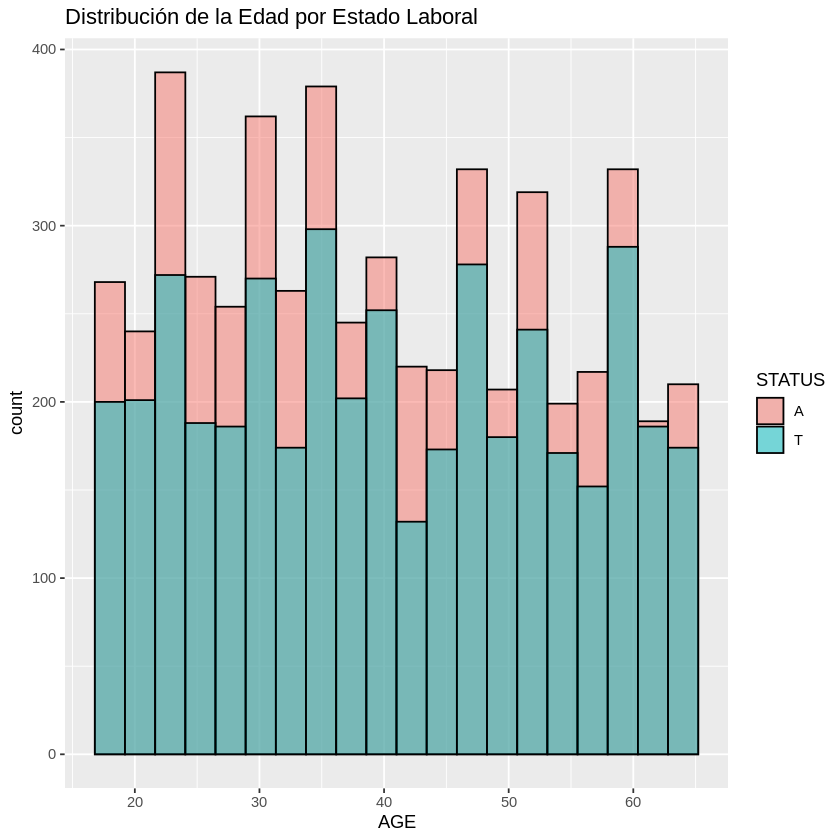

In [ ]:
ggplot(df, aes(x = AGE, fill = STATUS)) +
  geom_histogram(alpha = 0.5, bins = 20, position = "identity", color = "black") +
  labs(title = "Distribución de la Edad por Estado Laboral")

### 4.2 Distribución del sarlario anual

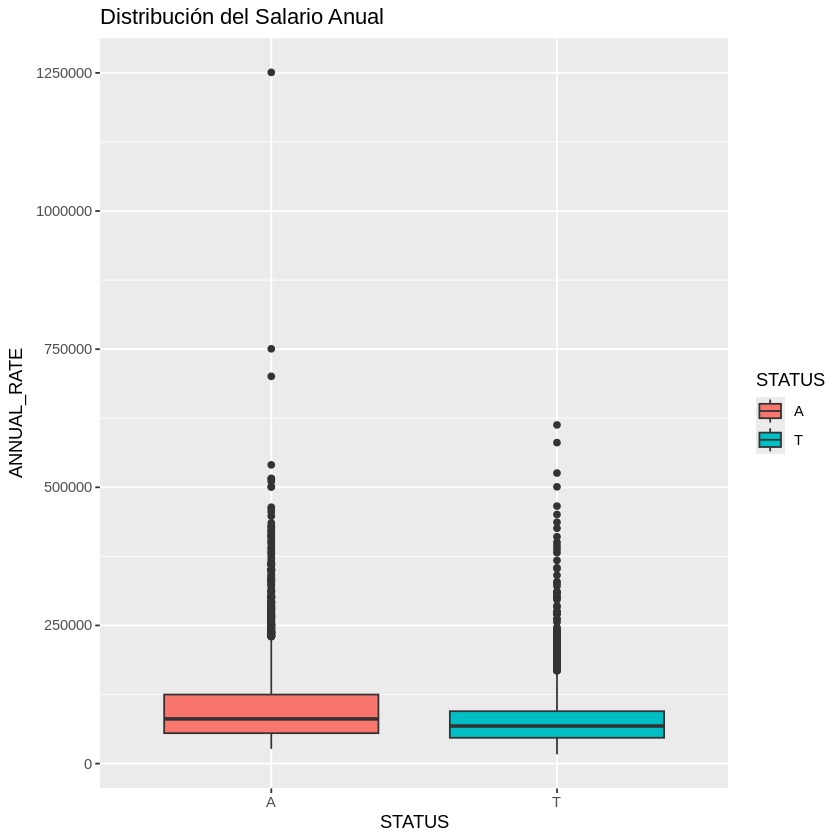

In [ ]:
ggplot(df, aes(x = STATUS, y = ANNUAL_RATE, fill = STATUS)) +
  geom_boxplot() + labs(title = "Distribución del Salario Anual")

### 4.3 Satisfacción por estado laboral

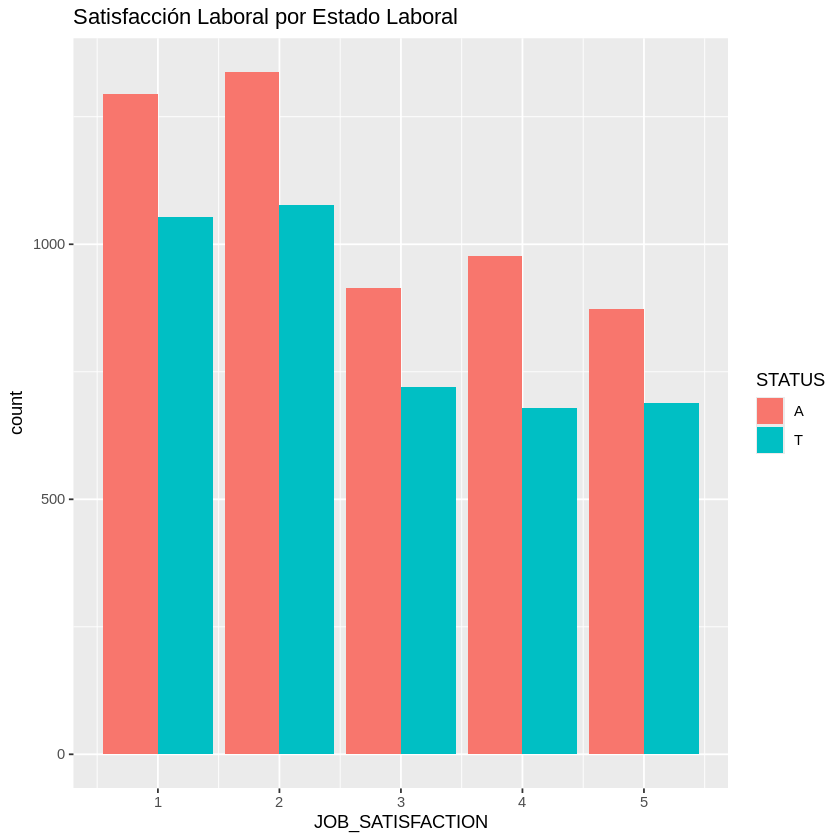

In [ ]:
ggplot(df, aes(x = JOB_SATISFACTION, fill = STATUS)) +
  geom_bar(position = "dodge") +
  labs(title = "Satisfacción Laboral por Estado Laboral")

### 4.4 Estado Civil por Estado Laboral

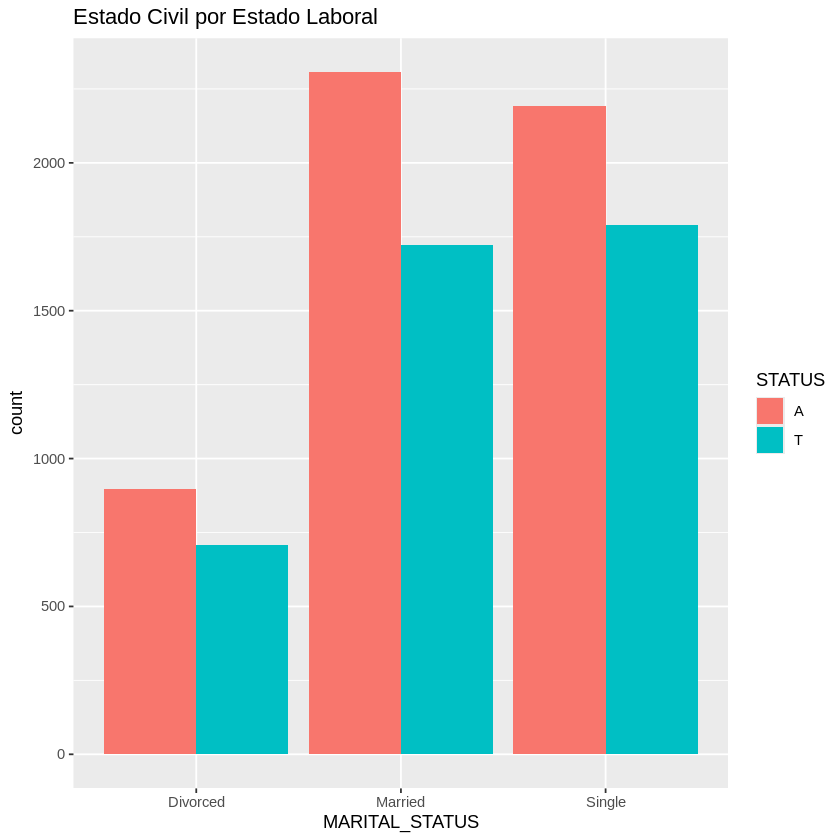

In [ ]:
ggplot(df, aes(x = MARITAL_STATUS, fill = STATUS)) +
  geom_bar(position = "dodge") +
  labs(title = "Estado Civil por Estado Laboral")

### 4.5 Distribución por grupo de trabajo

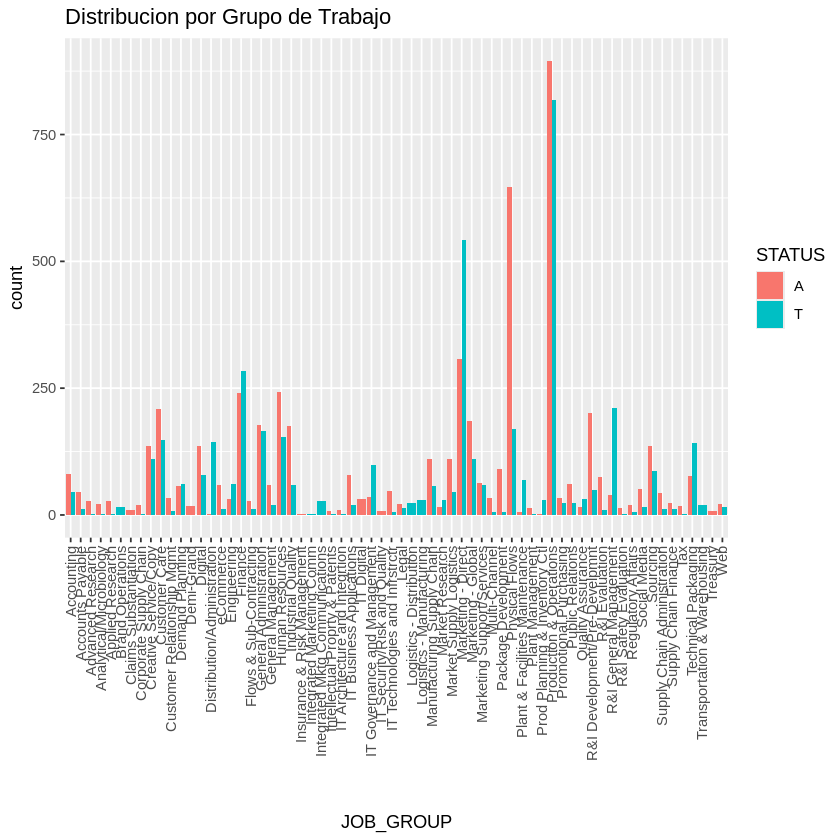

In [ ]:
ggplot(df, aes(x = JOB_GROUP, fill = STATUS)) +
  geom_bar(position = "dodge") +
  labs(title = "Distribucion por Grupo de Trabajo") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1))

In [9]:
df %>%
  group_by(JOB_GROUP, STATUS) %>%
  summarise(Cantidad = n())

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by JOB_GROUP and STATUS.
ℹ Output is grouped by JOB_GROUP.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(JOB_GROUP, STATUS))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


JOB_GROUP,STATUS,Cantidad
<chr>,<fct>,<int>
Accounting,A,80
Accounting,T,46
Accounts Payable,A,46
Accounts Payable,T,12
Advanced Research,A,28
Advanced Research,T,2
Analytical/Microbiology,A,22
Analytical/Microbiology,T,1
Applied Research,A,27


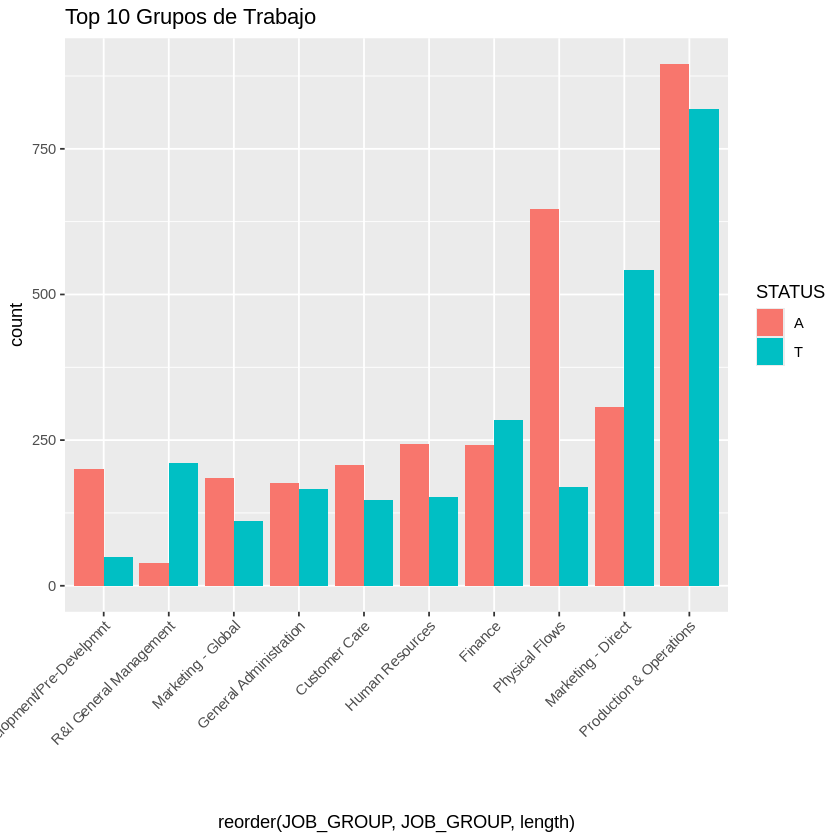

In [10]:
# Obtener los 10 JOB_GROUP más frecuentes
top10 <- df %>%
  count(JOB_GROUP, sort = TRUE) %>%
  slice_head(n = 10)

# Filtrar el dataframe original
df_top10 <- df %>%
  filter(JOB_GROUP %in% top10$JOB_GROUP)

# Graficar
ggplot(df_top10, aes(x = reorder(JOB_GROUP, JOB_GROUP, length), fill = STATUS)) +
  geom_bar(position = "dodge") +
  labs(title = "Top 10 Grupos de Trabajo") +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

### 4.6 Viajes Requeridos por Estado Laboral

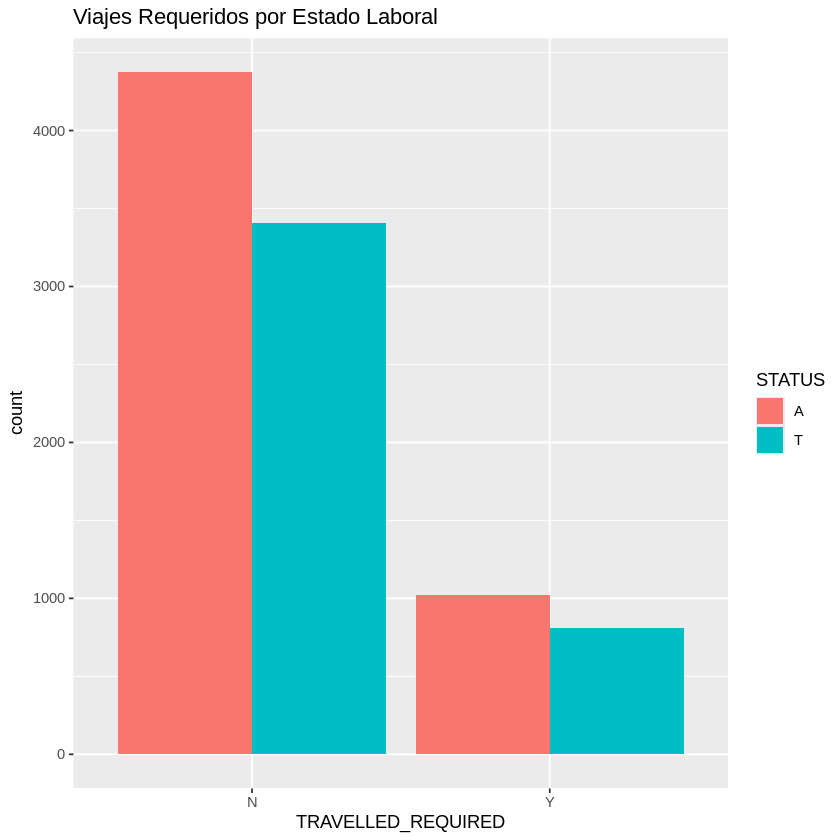

In [ ]:
ggplot(df, aes(x = TRAVELLED_REQUIRED, fill = STATUS)) +
  geom_bar(position = "dodge") +
  labs(title = "Viajes Requeridos por Estado Laboral")

### 4.7 Evaluacion de desempeño por estado laboral

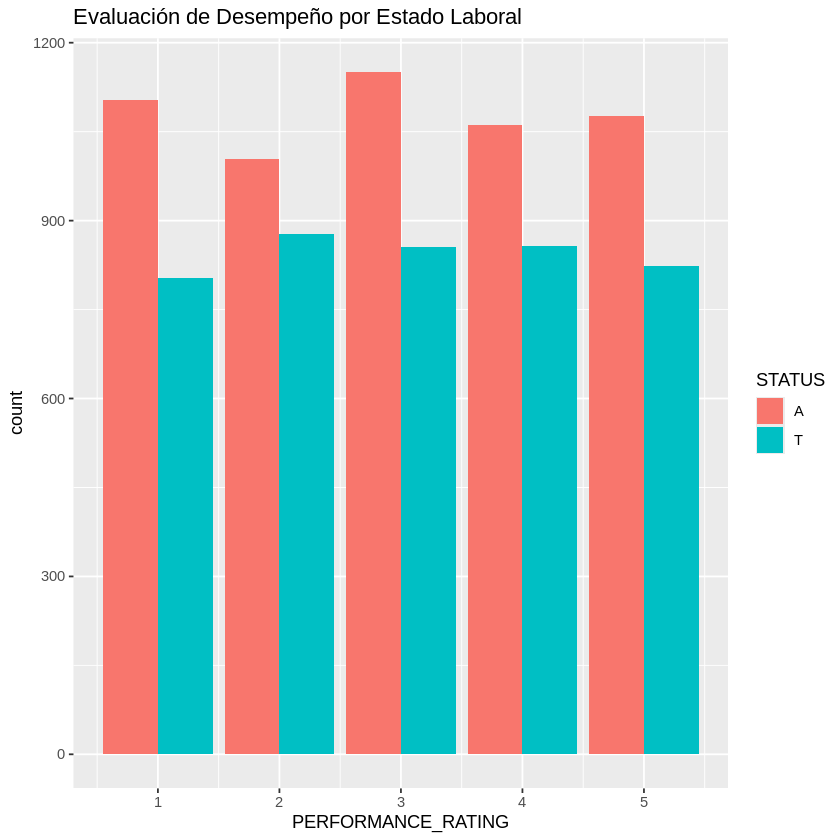

In [ ]:
ggplot(df, aes(x = PERFORMANCE_RATING, fill = STATUS)) +
  geom_bar(position = "dodge") +
  labs(title = "Evaluación de Desempeño por Estado Laboral")

---


## 5. Gráficos BIVARIADOS

### 5.1 Edad Vs Salario

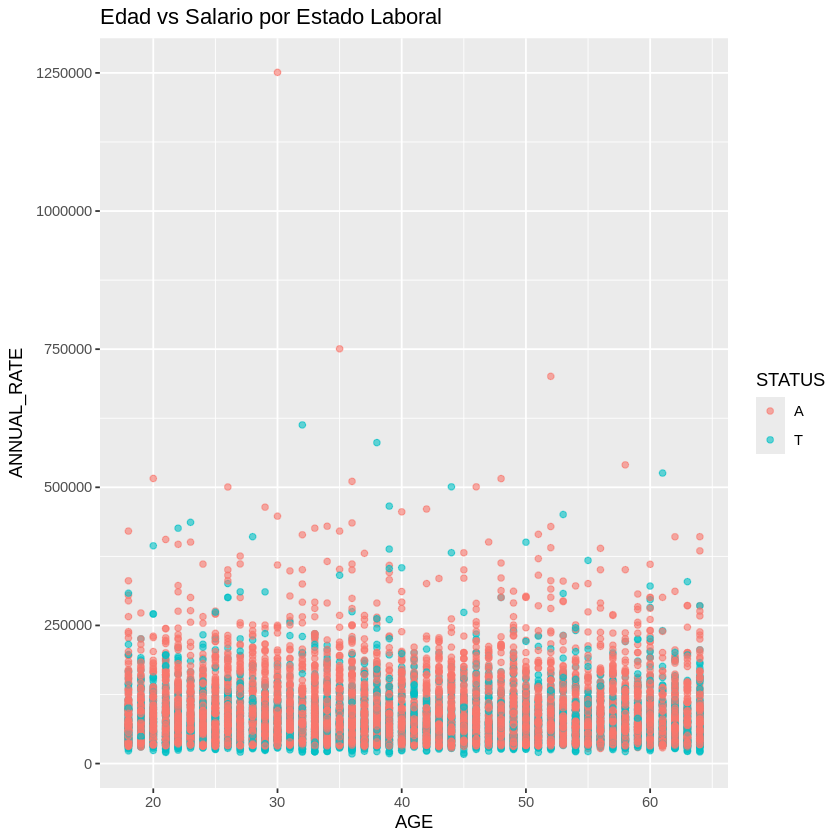

In [ ]:
ggplot(df, aes(x = AGE, y = ANNUAL_RATE, color = STATUS)) +
  geom_point(alpha = 0.6) +
  labs(title = "Edad vs Salario por Estado Laboral")

### 5.2 Salario Vs Satisfaccion laboral

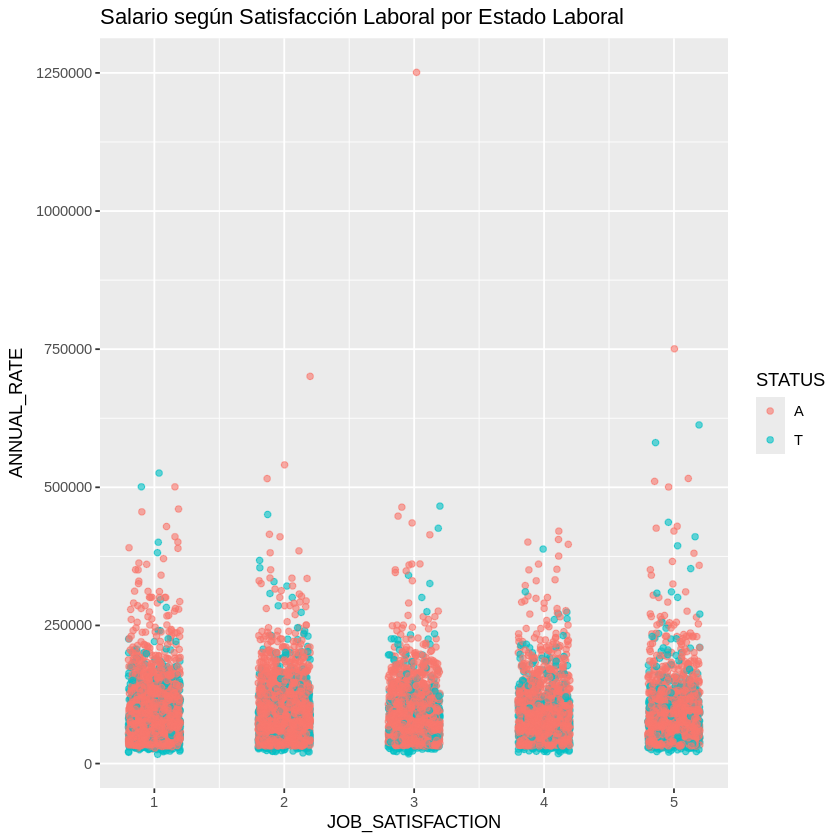

In [ ]:
ggplot(df, aes(x = JOB_SATISFACTION, y = ANNUAL_RATE, color = STATUS)) +
  geom_jitter(width = 0.2, alpha = 0.6) +
  labs(title = "Salario según Satisfacción Laboral por Estado Laboral")

### 5.3 Cambios de equipo vs satisfaccion

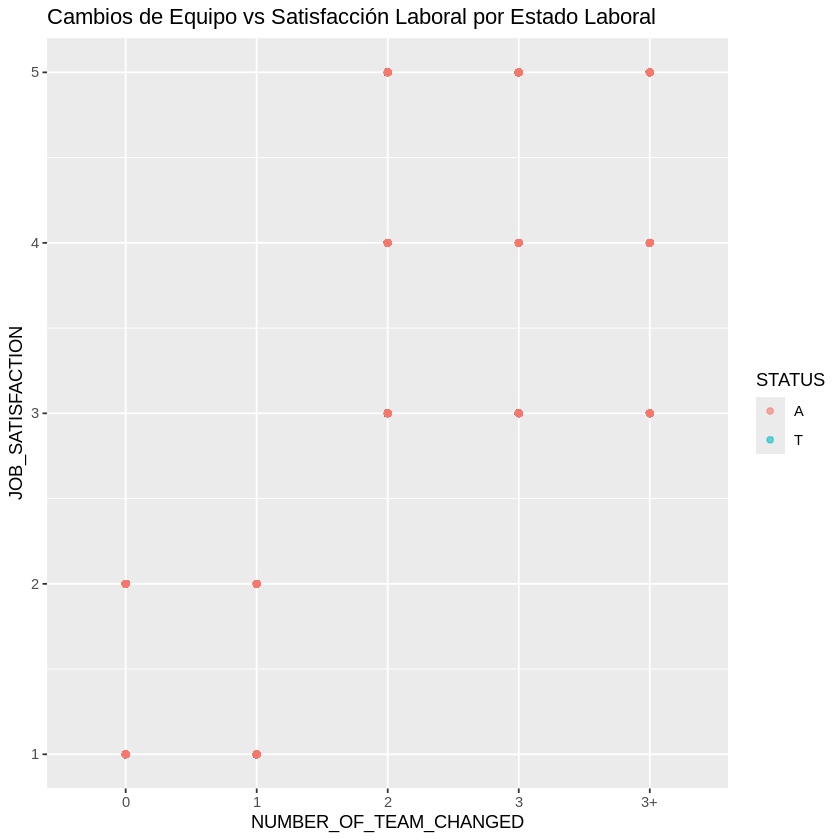

In [18]:
ggplot(df, aes(x = NUMBER_OF_TEAM_CHANGED, y = JOB_SATISFACTION, color = STATUS)) +
  geom_point(alpha = 0.6) +
  labs(title = "Cambios de Equipo vs Satisfacción Laboral por Estado Laboral")

### 5.4 Salario por genero y estatus (Boxplot)

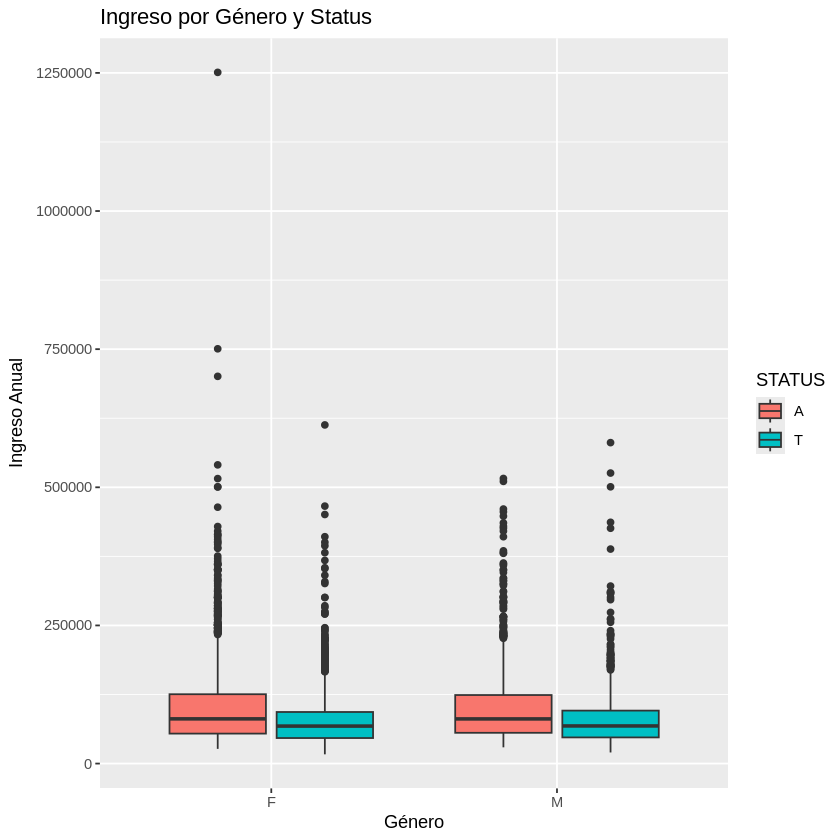

In [22]:
ggplot(df, aes(x = SEX, y = ANNUAL_RATE, fill = STATUS)) +
  geom_boxplot() +
  labs(
    title = "Ingreso por Género y Status",
    x = "Género",
    y = "Ingreso Anual"
  )

---


## 6. Perfil descriptivo consolidado por STATUS

In [16]:
df %>%
  group_by(STATUS) %>%
  summarise(
    edad_prom = mean(AGE, na.rm = TRUE),
    salario_prom = mean(ANNUAL_RATE, na.rm = TRUE),
    satsf_prom = mean(JOB_SATISFACTION, na.rm = TRUE),
    viajes_prop = mean(TRAVELLED_REQUIRED == "YES", na.rm = TRUE),
    primer_empleo_prop = mean(IS_FIRST_JOB == "YES", na.rm = TRUE),
    recontratado_prop = mean(REHIRE == "YES", na.rm = TRUE)
  )

STATUS,edad_prom,salario_prom,satsf_prom,viajes_prop,primer_empleo_prop,recontratado_prop
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A,39.84798,98604.85,2.776974,0,0,0
T,40.53983,77596.03,2.732575,0,0,0
